# Syllable representation sweeps (supplementary)

Is the syllable representation an arbitrary choice? Mouse identification as one choice is varied, everything else at the paper's values:

* **a — bins per epoch** (time-warping resolution: 1, 2, 5, 7, 10, 15, 20), 8 paw states. Re-binned from the same states files; 10 bins is the paper's (and reproduces its syllable file exactly).
* **b — number of paw states** (4, 6, 8, 10, 12, 16), 10 bins per epoch. The paper's paw clustering (`3.3_wavelet_clusters_uniform`: same training frames, normalisation and PCA) refitted at each K; 8 is the paper's.

**Score**: `lda_shrinkage_figures`' leave-one-session-out mouse identification (260 sessions, 56 mice; shrinkage chosen per fold by inner CV; ≤ 3 training sessions per mouse), 3 repeats. Filled: LDA space; open: syllable space (z-scored features, nearest centroid, no LDA), as in fig_lda panel b. **Error bars**: 95% CI, 2,000 bootstrap resamples of mice (each session's hit rate averaged over its repeats first). Dotted: chance (1/56). The paper's choice is ringed. The x axes are categorical (one evenly spaced position per value), not to scale.

**Computed by** `4_mice/syllable_sweeps.py` (cached in `data/syllable_sweeps/`); the paw-state syllables by `segmentation/paw_k_sweep.py`. Nothing is fitted here.

The number of features grows with both choices (in brackets under each tick: 36 × bins for a, 40 × (K + 1) for b); the shrinkage LDA picks its regularisation per fold, which is what makes the high-dimensional end fittable at all. A plateau there means *no more information*, not overfitting.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from datetime import date

FIGDIR = pathlib.Path.cwd().resolve()
while not (FIGDIR / 'fig_layout.py').exists() and FIGDIR != FIGDIR.parent:
    FIGDIR = FIGDIR / 'figure_generation' if (FIGDIR / 'figure_generation').exists() else FIGDIR.parent
PI = FIGDIR.parent
for p in [str(PI), str(FIGDIR), str(PI / '4_mice')]:
    if p not in sys.path:
        sys.path.insert(0, p)
import paper_style as ps
import fig_layout as fl
import syllable_sweeps as ss
ps.use('paper')
FIG = 'fig_syllable_sweeps'

N_BOOT, SEED = 2000, 0
PAPER = {'bins': 10, 'k': 8}
LDA_COLOR = '#8FCB8B'          # fig_lda's leave-one-session-out green
fs_small = plt.rcParams['font.size'] * 0.8

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Scores per value, bootstrapped over mice

In [2]:
def summarise(r, rng):
    # per session: hit rate over its repeats; then a bootstrap over mice of the session mean
    s = pd.DataFrame({'t': r['test_idx'], 'lda': r['correct'], 'syl': r['correct_syl']}).groupby('t').mean()
    mouse = r['mouse_of_session'][s.index]
    rows = pd.Series(np.arange(len(s))).groupby(mouse).apply(np.array)
    draws = [np.concatenate(rows.iloc[rng.integers(0, len(rows), len(rows))].to_numpy()) for _ in range(N_BOOT)]
    out = {'value': r['value'], 'n_features': r['n_features'], 'n_mice': len(r['mice'])}
    for c in ('lda', 'syl'):
        v = s[c].to_numpy()
        out[c] = v.mean()
        out[c + '_lo'], out[c + '_hi'] = np.percentile([v[d].mean() for d in draws], [2.5, 97.5])
    return out

RESULTS = {}
for sweep, values in ss.SWEEPS.items():
    rng = np.random.default_rng(SEED)
    rows = []
    for v in values:
        if (ss.OUT / sweep / f'loso_{v}.pkl').exists():
            rows.append(summarise(ss.loso(sweep, v), rng))
        else:
            print(f'{sweep} = {v}: not computed yet (python 4_mice/syllable_sweeps.py {sweep}) -- drawn without it')
    RESULTS[sweep] = pd.DataFrame(rows)
    print(sweep); print(RESULTS[sweep].round(3).to_string(index=False))

bins
 value  n_features  n_mice   lda  lda_lo  lda_hi   syl  syl_lo  syl_hi
     1          36      56 0.758   0.695   0.818 0.601   0.523   0.673
     2          72      56 0.826   0.776   0.874 0.676   0.609   0.743
     5         180      56 0.860   0.815   0.902 0.674   0.600   0.741
     7         252      56 0.864   0.810   0.911 0.690   0.619   0.757
    10         360      56 0.856   0.805   0.900 0.682   0.612   0.749
    15         540      56 0.873   0.826   0.916 0.690   0.622   0.759
    20         720      56 0.869   0.823   0.911 0.688   0.622   0.748


k
 value  n_features  n_mice   lda  lda_lo  lda_hi   syl  syl_lo  syl_hi
     4         200      56 0.810   0.757   0.860 0.605   0.526   0.678
     6         280      56 0.864   0.818   0.908 0.704   0.641   0.766
     8         360      56 0.856   0.806   0.904 0.682   0.610   0.749
    10         440      56 0.883   0.836   0.925 0.738   0.669   0.800
    12         520      56 0.867   0.822   0.907 0.755   0.687   0.817
    16         680      56 0.872   0.829   0.912 0.747   0.679   0.812


## The figure

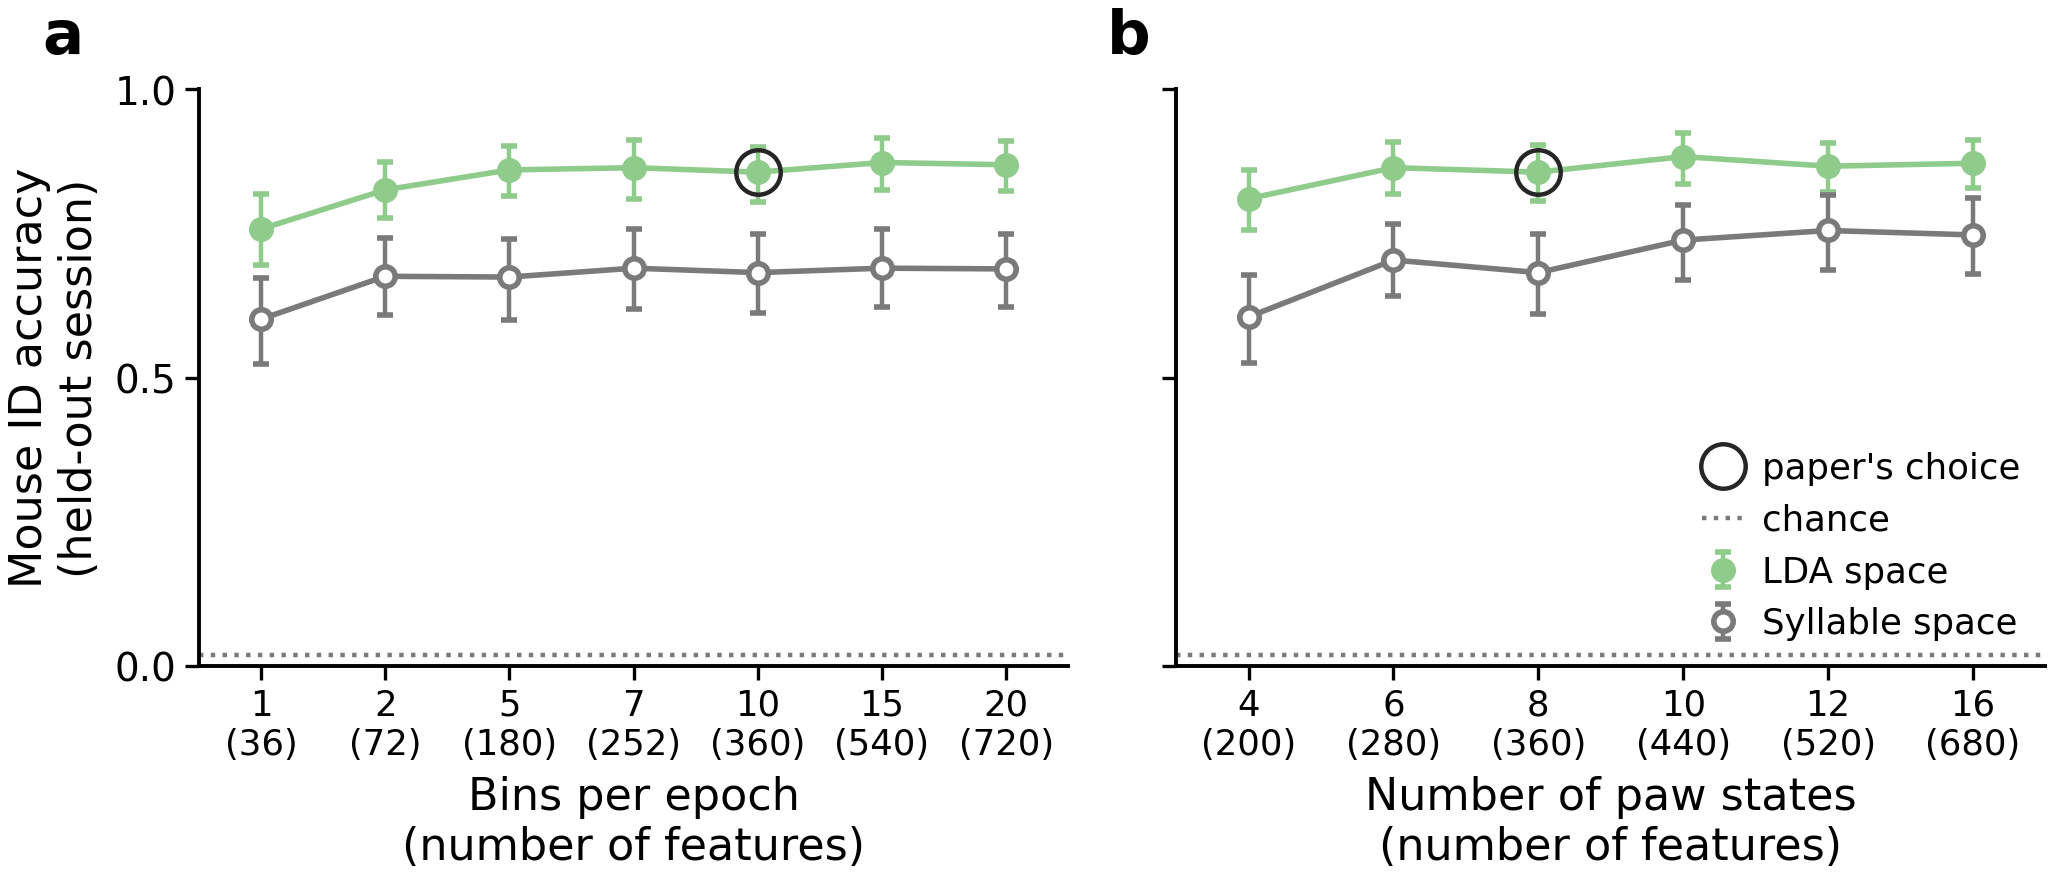

wrote figure_generation/figures/fig_syllable_sweeps_02-11-2026.svg


wrote figure_generation/figures/fig_syllable_sweeps.pdf
wrote figure_generation/figures/fig_syllable_sweeps.png


In [3]:
PANELS = [('bins', 'Bins per epoch', 'a'), ('k', 'Number of paw states', 'b')]

def draw(ax, sweep, xlabel):
    d = RESULTS[sweep]
    if not len(d):
        ax.text(0.5, 0.5, 'not computed yet', transform=ax.transAxes, ha='center', color=ps.NEUTRAL); return
    vals = d['value'].to_numpy()
    x = np.arange(len(vals))                      # categorical: one evenly spaced position per value
    for c, face, edge, lab in [('lda', LDA_COLOR, LDA_COLOR, 'LDA space'), ('syl', 'white', ps.NEUTRAL, 'Syllable space')]:
        ax.plot(x, d[c], color=edge, lw=1, zorder=2)
        ax.errorbar(x, d[c], yerr=[d[c] - d[c + '_lo'], d[c + '_hi'] - d[c]], fmt='o', ms=3.5, mfc=face, mec=edge,
                    ecolor=edge, elinewidth=0.8, capsize=1.5, zorder=3, label=lab)
    p = d[d['value'] == PAPER[sweep]]
    if len(p):
        ax.plot(x[vals == PAPER[sweep]], p['lda'], 'o', ms=8, mfc='none', mec='0.15', mew=0.8, zorder=4, label="paper's choice")
    ax.set_xlim(-0.5, len(x) - 0.5)
    ax.set_xticks(x)
    ax.set_xticklabels([f'{v}\n({n})' for v, n in zip(vals, d['n_features'])], fontsize=fs_small)
    ax.set_xlabel(xlabel + '\n(number of features)')
    ax.axhline(1 / d['n_mice'].iloc[0], color=ps.NEUTRAL, ls=':', lw=0.8, label='chance')
    ax.set_ylim(0, 1); ax.set_yticks([0, 0.5, 1])

fig, axes = plt.subplots(1, 2, figsize=(fl.FIG_WIDTH * 0.75, 2.4), sharey=True)
for ax, (sweep, xlabel, letter) in zip(axes, PANELS):
    draw(ax, sweep, xlabel)
    ax.text(-0.18 if letter == 'a' else -0.08, 1.04, letter, transform=ax.transAxes, fontweight='bold',
            fontsize=plt.rcParams['font.size'] + 3, va='bottom')
axes[0].set_ylabel('Mouse ID accuracy\n(held-out session)')
axes[1].legend(frameon=False, fontsize=fs_small, loc='lower right', handlelength=1.2)   # the free corner
fig.tight_layout()
plt.show()
OUT = FIGDIR / 'figures'
for path in [OUT / f"{FIG}_{date.today().strftime('%d-%m-%Y')}.svg", OUT / f'{FIG}.pdf', OUT / f'{FIG}.png']:
    fig.savefig(path, dpi=300)
    print('wrote', path.relative_to(PI))